# Text cleaning, lemmatisation and VADER scoring

Original file name: `Twitter Sentiment Analysis.ipynb`

**Not runnable from this repository.** It reads raw tweet text, which is not redistributed (see `data/README.md`). The code is shown for the method; outputs that displayed tweet text have been cleared, all other outputs are as executed.

In [1]:
# Install External Packages
!pip install -q neattext
!pip install -q contractions
!pip install -q vaderSentiment

In [2]:
#Import libraries
import neattext as nt
import neattext.functions as nfx
from neattext import TextFrame as textfr
import nltk
from nltk import pos_tag
nltk.download('stopwords')
from nltk.corpus import stopwords as sw
nltk.download('punkt')
from nltk.tokenize import word_tokenize as wt
from nltk.stem import WordNetLemmatizer as wnl
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')
from nltk.corpus import wordnet as wn
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer as SIA
import contractions as con
import pandas as pd
import numpy as np

[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [3]:
# Load dataset
Df = pd.read_csv('../data/raw/twitter_2021_dataset.csv', skipinitialspace=True)
Df

In [4]:
# Dropping 'URL' column
Df = Df.drop(columns=['url'])
Df

# Remove Spaces

In [5]:
# function to remove space
def space(tweet):
    text = ' '.join(tweet.split())
    return text

In [6]:
# apply funtion to remove space
Df['tweets'] = Df['text'].apply(space)
Df['text'] = Df['tweets']
del Df['tweets']
Df

In [7]:
# save changes
Df.to_csv('../data/raw/twitter_2021_dataset.csv', encoding='utf-8-sig', index=False)

In [8]:
# Load dataset
TweetDf = pd.read_csv('../data/raw/twitter_2021_dataset.csv', skipinitialspace=True)
TweetDf

In [9]:
# Scan text noise
TweetDf['Text_noise'] = TweetDf['text'].apply(lambda x : nt.TextFrame(x).noise_scan()['text_noise'])

In [10]:
TweetDf

# Text Preprocessing
#### This function removes the following from the text:
+ Emails 
+ Hashtags
+ Userhandles
+ HTML tags
+ Numbers
+ Phone Numbers
+ URLs
+ Tags
+ Currency Symbols
+ Mulitple Spaces
+ Fixes Contractions

In [11]:
def clean_text(text):
    clean = con.fix(text)
    clean = clean.replace("&amp;", "")
    clean = nfx.remove_emails(clean)
    docx = textfr(clean)
    docx.remove_hashtags().remove_userhandles().remove_html_tags().remove_urls().remove_numbers().remove_phone_numbers().remove_currency_symbols().remove_multiple_spaces()
    return docx

TweetDf['Clean_text'] = TweetDf['text'].apply(lambda text: clean_text(text))
TweetDf.to_csv('../data/raw/twitter_2021_dataset.csv', encoding='utf-8-sig', index=False)
TweetDf

# Text Processing
####  These functions do the following processes:  
+ Removes Punctuations
+ Removes Stop Words
+ Tokenization
+ Part of Speech Tagging
+ Lemmatization

In [12]:
# Load dataset
TweetDf = pd.read_csv('../data/raw/twitter_2021_dataset.csv', skipinitialspace=True)
TweetDf

In [13]:
#Check if text was not cleaned
TweetDf['Clean_text'] = TweetDf['Clean_text'].fillna(" ")
TweetDf['Clean_text'].isnull().sum()

0

In [14]:
#Custom nltk.stopwords list
sw_list = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 
                  'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 
                  'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 
                  'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 
                  'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 
                  'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 
                  'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 
                  'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 
                  'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such','only', 'own',
                  'same', 'so', 'than', 'too', 'very', 's', 't', 'can', 'will', 'just', 'don', "don't", 'should', 
                  "should've", 'now', 'd', 'll', 'm', 'o', 're', 've', 'y', 'ain', 'aren', "aren't", 'couldn', "couldn't", 'didn', 
                  "didn't", 'doesn', "doesn't", 'hadn', "hadn't", 'hasn', "hasn't", 'haven', "haven't", 'isn', "isn't", 'ma', 
                  'mightn', "mightn't", 'mustn', "mustn't", 'needn', "needn't", 'shan', "shan't", 'shouldn', "shouldn't", 'wasn', 
                  "wasn't", 'weren', "weren't", 'won', "won't", 'would', 'wouldn', "wouldn't"]
lemmatizer = wnl()


def Token_text(sentence):
    sentence = sentence.translate(str.maketrans('', '', """()-__--`+[]{};:''"\,<>./@|#$%^&*``_~"""))
    sentence = wt(sentence)
    filtered_sentence=[]
    for word in sentence:
        if word.lower() not in sw_list:
            filtered_sentence.append(word)
    return filtered_sentence


def POS_tags(tags):
    if tags.startswith('J'):
        return wn.ADJ
    elif tags.startswith('V'):
        return wn.VERB
    elif tags.startswith('N'):
        return wn.NOUN
    elif tags.startswith('R'):
        return wn.ADV
    else:         
        return None


def Lemmatization(sentence):
    Tweet_tag = nltk.pos_tag(Token_text(sentence)) 
    wn_tag = list(map(lambda x: (x[0], POS_tags(x[1])), Tweet_tag))
    lemma_sentence = []
    for w, t in wn_tag:
        if t is None:
            lemma_sentence.append(w)
        else:       
            lemma_sentence.append(lemmatizer.lemmatize(w, t))
    lemma_sentence = " ".join(lemma_sentence)
    return lemma_sentence

TweetDf['Processed_text'] = TweetDf['Clean_text'].apply(lambda Clean_text: Lemmatization(Clean_text))
TweetDf

In [15]:
# Scan processed text noise
TweetDf['Processed_text_noise'] = TweetDf['Processed_text'].apply(lambda x : nt.TextFrame(x).noise_scan()['text_noise'])
TweetDf

# Vader Sentimental Analysis (NLP)

In [16]:
# Applying sentimental analysis scores on processed text
sia = SIA()
TweetDf['Scores'] = TweetDf['Processed_text'].apply(lambda Processed_text: sia.polarity_scores(Processed_text))
TweetDf

In [17]:
# Applying sentiment based on overall compound
TweetDf['Compound'] = TweetDf['Scores'].apply(lambda score_dict: score_dict['compound'])
TweetDf['Sentiment']=''
TweetDf.loc[TweetDf.Compound>0,'Sentiment']='POSITIVE'
TweetDf.loc[TweetDf.Compound==0,'Sentiment']='NEUTRAL'
TweetDf.loc[TweetDf.Compound<0,'Sentiment']='NEGATIVE'
TweetDf

<Axes: title={'center': 'sentiment analysis'}>

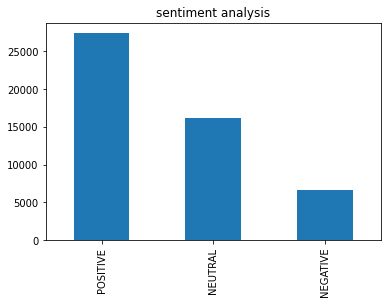

In [18]:
TweetDf.Sentiment.value_counts().plot(kind='bar',title="sentiment analysis")

In [20]:
TweetDf.Sentiment.value_counts()

POSITIVE    27405
NEUTRAL     16188
NEGATIVE     6700
Name: Sentiment, dtype: int64

In [21]:
# save file
TweetDf.to_csv('../data/raw/Twitter_Sentiment_Analysis_Dataset.csv', encoding='utf-8-sig', index=False)